In [69]:
!pip install pandas numpy matplotlib seaborn sqlalchemy pymysql


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

connection_url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="Neha@030205",
    host="localhost",
    port=3306,
    database="loan_db")
engine = create_engine(connection_url)

In [71]:
df = pd.read_sql("select * from  loans_fact", engine)
approval = pd.read_sql("select * from lk_year_approval", engine)

df["issue_date"] = pd.to_datetime(df["issue_date"], errors="coerce")

print("Dataset shape:", df.shape)
print("Unique loan IDs:", df["loan_id"].nunique())
print("Approval data shape:", approval.shape)

assert df["loan_id"].nunique() == len(df), "Duplicate loan IDs found!"

print("\nMySQL connection successful!")
print(df.head())

Dataset shape: (2498, 30)
Unique loan IDs: 2498
Approval data shape: (6, 4)

MySQL connection successful!
   loan_id issue_date  issue_year  loan_amount  term_months  \
0   346692 2015-04-01        2015         2200           36   
1   691328 2014-10-01        2014         5600           36   
2  1550798 2013-07-01        2013        21000           36   
3  2826187 2013-01-01        2013        24000           60   
4  2838358 2013-01-01        2013        13000           36   

   interest_rate_pct  monthly_installment grade sub_grade           loan_type  \
0              11.53                   73     B        B5         educational   
1              12.49                  187     B        B5         credit_card   
2              13.68                  714     C        C1         credit_card   
3              21.49                  656     E        E3  debt_consolidation   
4              11.14                  426     B        B2         credit_card   

   ... is_closed_status defa

In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2498 entries, 0 to 2497
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype        
---  ------                        --------------  -----        
 0   loan_id                       2498 non-null   int64        
 1   issue_date                    2498 non-null   datetime64[s]
 2   issue_year                    2498 non-null   int64        
 3   loan_amount                   2498 non-null   int64        
 4   term_months                   2498 non-null   int64        
 5   interest_rate_pct             2498 non-null   float64      
 6   monthly_installment           2498 non-null   int64        
 7   grade                         2498 non-null   str          
 8   sub_grade                     2498 non-null   str          
 9   loan_type                     2498 non-null   str          
 10  home_ownership                2498 non-null   str          
 11  income_verification           2498 non-null   str     

In [73]:
# Check total rows and unique loan IDs
print("Total Rows:", len(df))
print("Unique Loan IDs:", df["loan_id"].nunique())

# Check duplicate loan IDs
print("Duplicate Loan IDs:", df["loan_id"].duplicated().sum())

# Check loan ID range
print("Minimum Loan ID:", df["loan_id"].min())
print("Maximum Loan ID:", df["loan_id"].max())

Total Rows: 2498
Unique Loan IDs: 2498
Duplicate Loan IDs: 0
Minimum Loan ID: 346692
Maximum Loan ID: 145622433


In [74]:
df.describe()

,loan_id,issue_date,issue_year,loan_amount,term_months,interest_rate_pct,monthly_installment,employment_years,annual_income,debt_to_income_pct,credit_score,is_closed_status,default_flag,outstanding_principal,principal_repaid,issue_year_approval_rate_pct
count,2.498000e+03,2498,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000,2498.000000
mean,8.379990e+07,2016-07-15 15:21:45,2016.058046,15117.353883,42.859888,13.058519,447.702162,5.578863,76636.716974,18.392742,700.476781,0.579664,0.117294,4319.713771,9499.950761,8.648078
min,3.466920e+05,2013-01-01 00:00:00,2013.000000,1000.000000,36.000000,5.310000,31.000000,0.000000,3600.000000,0.000000,662.000000,0.000000,0.000000,0.000000,68.000000,4.950000
25%,5.206370e+07,2015-06-01 00:00:00,2015.000000,8000.000000,36.000000,9.490000,250.000000,2.000000,48000.000000,11.870000,677.000000,0.000000,0.000000,0.000000,3000.000000,5.900000
50%,8.813464e+07,2016-08-01 00:00:00,2016.000000,12800.000000,36.000000,12.620000,376.000000,5.000000,65000.000000,17.665000,692.000000,1.000000,0.000000,0.000000,6762.000000,8.350000
75%,1.240517e+08,2017-11-01 00:00:00,2017.000000,20000.000000,60.000000,15.990000,602.000000,10.000000,93000.000000,24.265000,717.000000,1.000000,0.000000,6316.000000,13297.000000,12.840000
max,1.456224e+08,2018-12-01 00:00:00,2018.000000,40000.000000,60.000000,30.940000,1431.000000,10.000000,592000.000000,96.600000,837.000000,1.000000,1.000000,38575.000000,40000.000000,15.050000
std,4.265019e+07,NaN,1.523095,9350.149300,10.845568,4.780059,273.215158,3.761458,46360.346453,9.171695,33.000280,0.493712,0.321835,7354.592382,8585.646998,3.354378


In [75]:
df.head()

,loan_id,issue_date,issue_year,loan_amount,term_months,interest_rate_pct,monthly_installment,grade,sub_grade,loan_type,...,is_closed_status,default_flag,outstanding_principal,principal_repaid,credit_score_band,debt_to_income_band,income_band,loan_size_band,loan_type_group,issue_year_approval_rate_pct
0,346692,2015-04-01,2015,2200,36,11.53,73,B,B5,educational,...,1,0,0,2200,625-699,2: 10-20,2-Low Mid,1-Small (<10k),All other purposes,12.84
1,691328,2014-10-01,2014,5600,36,12.49,187,B,B5,credit_card,...,1,1,0,3010,625-699,3: 20-30,1-Low,1-Small (<10k),Credit card,10.86
2,1550798,2013-07-01,2013,21000,36,13.68,714,C,C1,credit_card,...,1,0,0,21000,625-699,3: 20-30,3-Upper Mid,2-Medium (10k-25k),Credit card,15.05
3,2826187,2013-01-01,2013,24000,60,21.49,656,E,E3,debt_consolidation,...,1,0,0,24000,625-699,2: 10-20,3-Upper Mid,2-Medium (10k-25k),Debt consolidation,15.05
4,2838358,2013-01-01,2013,13000,36,11.14,426,B,B2,credit_card,...,1,0,0,13000,700-749,4: 30+,3-Upper Mid,2-Medium (10k-25k),Credit card,15.05


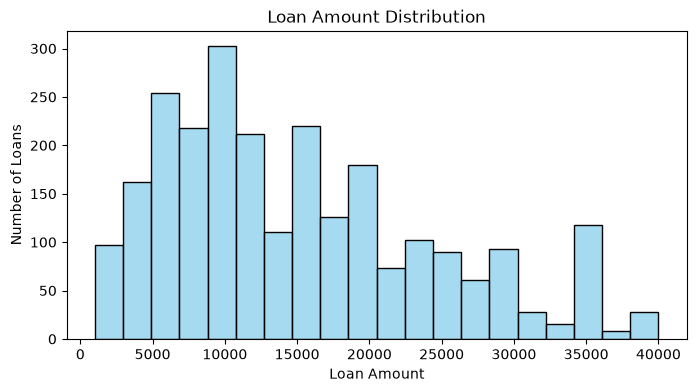

In [76]:
plt.figure(figsize=(8, 4)) 
sns.histplot(data=df, x="loan_amount", bins=20, color="skyblue") 
plt.title("Loan Amount Distribution") 
plt.xlabel("Loan Amount") 
plt.ylabel("Number of Loans") 
plt.show()

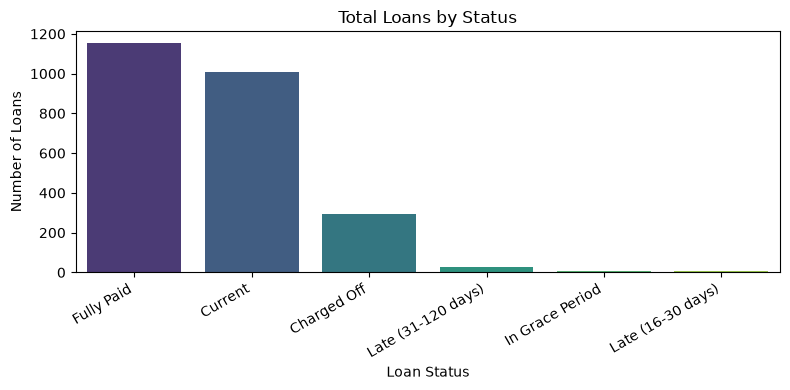

In [77]:
Status_count = df["loan_status"].value_counts() 
plt.figure(figsize=(8, 4)) 
sns.barplot( x=Status_count.index, y=Status_count.values, hue=Status_count.index, legend=False, palette="viridis" ) 
plt.title("Total Loans by Status")
plt.xlabel("Loan Status") 
plt.ylabel("Number of Loans")
plt.xticks(rotation=30, ha="right") 
plt.tight_layout() 
plt.show()

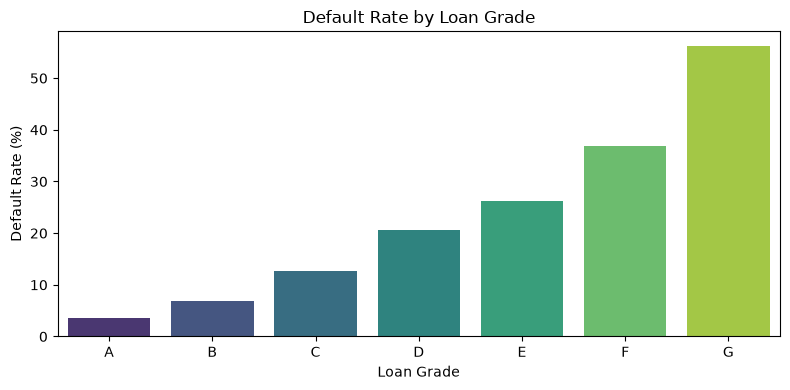

In [78]:
Grade_default = df.groupby("grade")["default_flag"].mean() * 100
plt.figure(figsize=(8, 4))
sns.barplot(
    x=Grade_default.index,
    y=Grade_default.values,
    hue=Grade_default.index,
    legend=False,
    palette="viridis")
plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()


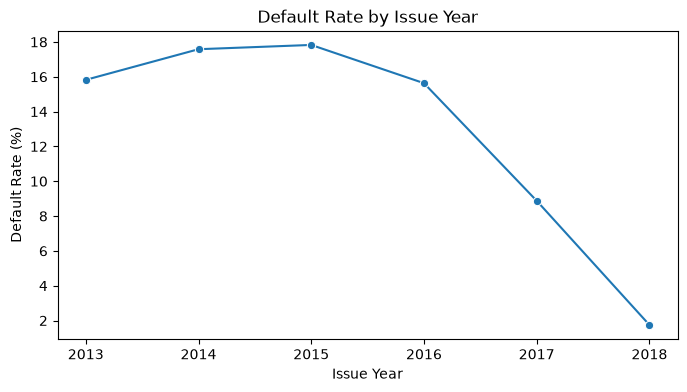

In [80]:
Year_default = df.groupby("issue_year")["default_flag"].mean() * 100
plt.figure(figsize=(8, 4))
sns.lineplot(x=Year_default.index, y=Year_default.values, marker="o")
plt.title("Default Rate by Issue Year")
plt.xlabel("Issue Year")
plt.ylabel("Default Rate (%)")
plt.show()

In [81]:
# Calculate financial ratios
df["loan_to_income"] = df["loan_amount"] / df["annual_income"].replace(0, np.nan)
df["payment_burden"] = (df["monthly_installment"] * 12) / df["annual_income"].replace(0, np.nan)

# Classify loan status
df["loan_status_class"] = df["loan_status"].map({
    "Fully Paid": "Good",
    "Charged Off": "Default",
    "Current": "Active",
    "Late (16-30 days)": "Watchlist",
    "Late (31-120 days)": "Watchlist",
    "In Grace Period": "Watchlist"
}).fillna("Other")

# Identify watchlist loans
df["watchlist_flag"] = df["loan_status"].isin([
    "Late (16-30 days)",
    "Late (31-120 days)",
    "In Grace Period"
]).astype(int)

print(df[["loan_id", "loan_to_income", "payment_burden",
          "loan_status_class", "watchlist_flag"]].head())

print("\nLoan Classification:")
print(df["loan_status_class"].value_counts())

print("\nWatchlist Loans:", df["watchlist_flag"].sum())

   loan_id  loan_to_income  payment_burden loan_status_class  watchlist_flag
0   346692        0.034109        0.013581              Good               0
1   691328        0.140000        0.056100           Default               0
2  1550798        0.262500        0.107100              Good               0
3  2826187        0.369231        0.121108              Good               0
4  2838358        0.147545        0.058019              Good               0

Loan Classification:
loan_status_class
Good         1155
Active       1010
Default       293
Watchlist      40
Name: count, dtype: int64

Watchlist Loans: 40


            total_loans  defaulted_loans  default_rate
issue_year                                            
2013                158               25         15.82
2014                258               48         18.60
2015                436               87         19.95
2016                336               78         23.21
2017                194               45         23.20
2018                 66               10         15.15


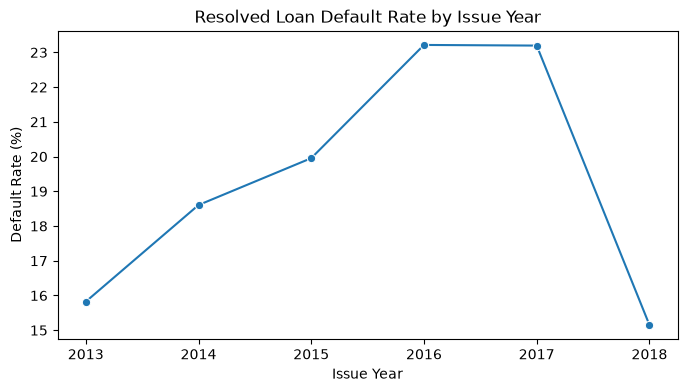

In [82]:
# Select completed loans
resolved = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])]

# Calculate yearly performance
Vintage = resolved.groupby("issue_year").agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum")
)

Vintage["default_rate"] = (
    Vintage["defaulted_loans"] / Vintage["total_loans"] * 100
)

print(Vintage.round(2))

# Visualize yearly performance
plt.figure(figsize=(8, 4))

sns.lineplot(x=Vintage.index, y=Vintage["default_rate"], marker="o")

plt.title("Resolved Loan Default Rate by Issue Year")
plt.xlabel("Issue Year")
plt.ylabel("Default Rate (%)")
plt.show()

In [83]:
# Create summary tables
Grade_summary = df.groupby("grade")["default_flag"].mean().reset_index()
Year_summary = df.groupby("issue_year")["default_flag"].mean().reset_index()

In [84]:
# Export results to MySQL
df.to_sql("loan_python_features", engine, if_exists="replace", index=False)

Grade_summary.to_sql("grade_summary", engine, if_exists="replace", index=False)

Vintage.reset_index().to_sql("vintage_summary", engine, if_exists="replace", index=False)

print("Python results successfully exported to MySQL!")

Python results successfully exported to MySQL!


In [85]:
# Download Grade Summary
Grade_summary.to_csv("grade_summary.csv", index=False)

# Download Loan Python Features
df.to_csv("loan_python_features.csv", index=False)

# Download Vintage Summary
Vintage.reset_index().to_csv("vintage_summary.csv", index=False)

print("All 3 tables exported successfully!")

All 3 tables exported successfully!
